# Fiducial Analysis for FBOT Survey

Let's consider the following very simplistic survey:

- We are awarded a total **on-target time allocation** $T_{\rm survey}$ for a survey of FBOTs.
- We have effectively complete priority; however, TOO interrupts will certainly be a concern down the line. For now,
  we assume that we can observe uninterrupted for the entire survey.
- For each field that we observe, we have a non-overlapping area $\langle \Omega_{\rm unique}\rangle = \eta \Omega_{\rm FOV}$.
- We have a revist time $\delta t_0$.

We wish to know how many LFBOTs we could feasibly hope to see.

With a revisit time of $\delta t_0$, and a single-dwell time of $t_d$, we can observe at most

$$
N_{\rm f,\;max} = \frac{\delta t_0}{t_d} = 96 \left(\frac{\delta t_0}{1\ {\rm day}}\right)
$$

unique fields. The resulting area would be

$$
\Omega_{\rm max} = N_{\rm f,\;max} \langle \Omega_{\rm unique}\rangle = \frac{\delta t_0}{t_d} \eta \Omega_{\rm FOV} = 1152 \;{\rm deg}^2 \eta \left(\frac{\delta t_0}{1\ {\rm day}}\right) \left(\frac{\Omega_{\rm FOV}}{12 {\rm deg}^2}\right).
$$

We'd be able to observe each field a total of

$$
N_e = \frac{T_{\rm survey}}{\delta t_0} = 10 \left(\frac{T_{\rm survey}}{10\ {\rm days}}\right) \left(\frac{\delta t_0}{1\ {\rm day}}\right)^{-1}
$$


If we want to target an **average cadence** of $\tau$, then

$$
\Omega_{\rm max} = 1152 \;{\rm deg}^2 \frac{2\eta^2}{3\eta - 1} \left(\frac{\tau}{1\ {\rm day}}\right) \left(\frac{\Omega_{\rm FOV}}{12 {\rm deg}^2}\right).
$$

If LFBOTs are entirely detectable at this cadence out to a target depth of $z$, then the maximal number of LFBOTs that we could hope to detect is

$$
N_{\rm max} \le 0.00961\;{\rm sr\;yr} \frac{2\eta^2}{3\eta - 1}  \left(\frac{\tau}{1\ {\rm day}}\right) \left(\frac{\Omega_{\rm FOV}}{12 {\rm deg}^2}\right) \left(\frac{T_{\rm survey}}{10\ {\rm days}}\right) \int_0^z \frac{R_{\rm LFBOT}(z')}{1+z'} \frac{dV}{dz'} dz',
$$

where the prefactor is $\Omega_{\rm max}\,T_{\rm survey} = 1152\ {\rm deg}^2 \times 10\ {\rm d} = 0.351\ {\rm sr} \times 0.0274\ {\rm yr}$ at $\eta = 1$, $\tau = 1$ day. The $1/(1+z)$ converts the rest-frame rate to an observer-frame rate.

## Expected yield per day of survey time

Fiducial design: $\tau = \delta t_0 = 1$ day, **no overlap** ($\eta = 1$), $\Omega_{\rm FOV} = 12\ {\rm deg}^2$, $t_d = 15$ min, so each day of survey time covers $\Omega_{\rm max} = 1152\ {\rm deg}^2$.

The LFBOT volumetric rate is bounded by $R_{\rm LFBOT} = 0.3$ – $420\ {\rm yr^{-1}\,Gpc^{-3}}$ (constant in $z$). The shaded band below is the expected number of LFBOTs per day of survey time, for LFBOTs that are fully detectable out to a depth $z$:

$$
\frac{N}{T_{\rm survey}} = \Omega_{\rm max}\, R_{\rm LFBOT} \int_0^z \frac{1}{1+z'} \frac{dV}{dz'\,d\Omega}\, dz'.
$$

In [17]:
import numpy as np
import matplotlib.pyplot as plt
from astropy import units as u
from astropy.cosmology import Planck18 as cosmo
from scipy.integrate import cumulative_trapezoid

# --- Survey design ---------------------------------------------------------
omega_fov = 12 * u.deg**2   # field of view
t_dwell = 15 * u.min        # single-dwell time
cadence = 1 * u.day         # revisit time (delta t_0 = tau)
eta = 1.0                   # unique-area fraction per field (1 = no overlap)
duty = 1.0                  # on-target efficiency (1 = uninterrupted, see intro)
t_survey = 1 * u.day        # report yields per day of survey time

# --- LFBOT volumetric rate bounds (constant in z) ---------------------------
rate_low = 0.3 / (u.yr * u.Gpc**3)
rate_high = 420 / (u.yr * u.Gpc**3)

# Unique area covered per cadence: N_f,max * eta * Omega_FOV  (1152 deg^2 here).
n_fields = (cadence / t_dwell).decompose().value
omega_max = (n_fields * eta * omega_fov).to(u.sr)

# Observer-frame comoving volume per steradian out to z, with the 1/(1+z) time dilation.
z = np.linspace(0, 1, 2001)
dVdz = cosmo.differential_comoving_volume(z).to(u.Gpc**3 / u.sr).value
volume = cumulative_trapezoid(dVdz / (1 + z), z, initial=0) * u.Gpc**3 / u.sr

def daily_yield(rate):
    """Expected LFBOTs per `t_survey` as a function of depth z."""
    return (rate * omega_max * t_survey * duty * volume).to(u.dimensionless_unscaled).value

yield_low, yield_high = daily_yield(rate_low), daily_yield(rate_high)
print(f"{n_fields:.0f} fields/cadence -> Omega_max = {omega_max.to(u.deg**2):.0f}")

96 fields/cadence -> Omega_max = 1152 deg2


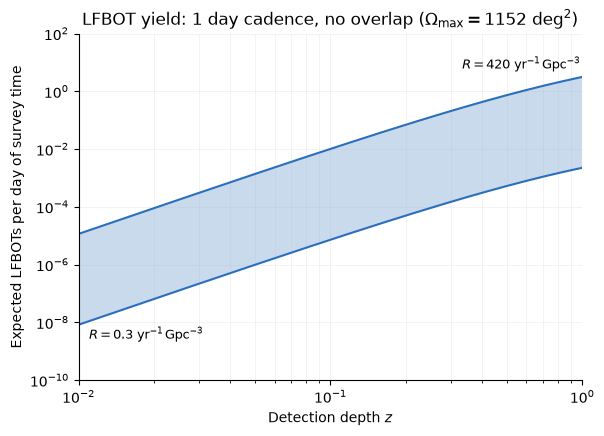

In [18]:
fig, ax = plt.subplots(figsize=(6.5, 4.5))
color = "#2a6fbb"

ax.fill_between(z[1:], yield_low[1:], yield_high[1:], color=color, alpha=0.25, lw=0)
ax.plot(z[1:], yield_low[1:], color=color, lw=1.5)
ax.plot(z[1:], yield_high[1:], color=color, lw=1.5)
ax.text(0.98, yield_high[-1] * 1.5, r"$R = 420\ {\rm yr^{-1}\,Gpc^{-3}}$", ha="right", va="bottom", fontsize=9)
ax.text(0.011, yield_low[np.searchsorted(z, 0.011)] / 1.6, r"$R = 0.3\ {\rm yr^{-1}\,Gpc^{-3}}$", ha="left", va="top", fontsize=9)

ax.set(xscale="log", yscale="log", xlim=(0.01, 1), ylim=(1e-10, 1e2), xlabel="Detection depth $z$",
       ylabel="Expected LFBOTs per day of survey time",
       title=r"LFBOT yield: 1 day cadence, no overlap ($\Omega_{\rm max}=1152\ {\rm deg}^2$)")
ax.grid(alpha=0.2, which="both", lw=0.5)
for side in ("top", "right"):
    ax.spines[side].set_visible(False)
plt.show()

In [19]:
print(f"{'z':>5}  {'low (0.3)':>10}  {'high (420)':>10}   [LFBOTs / day of survey]")
for z_i in (0.1, 0.2, 0.5, 1.0):
    i = np.searchsorted(z, z_i)
    print(f"{z[i]:5.2f}  {yield_low[i]:10.2g}  {yield_high[i]:10.2g}")

    z   low (0.3)  high (420)   [LFBOTs / day of survey]
 0.10     7.2e-06        0.01
 0.20       5e-05        0.07
 0.50     0.00052        0.73
 1.00      0.0022         3.1


## Survey duration needed for 10 events

Since the yield scales linearly with survey time, the duration needed to detect $N_{\rm target} = 10$ LFBOTs is

$$
T_{10} = \frac{N_{\rm target}}{\Omega_{\rm max}\, R_{\rm LFBOT}\, \eta_{\rm duty} \int_0^z \frac{1}{1+z'} \frac{dV}{dz'\,d\Omega}\, dz'},
$$

shown below as a function of the volumetric rate for several detection depths (same fiducial design as above).

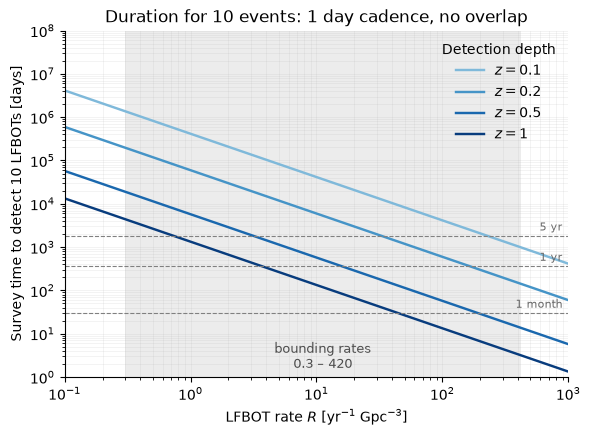

Survey days needed for 10 events
     R  z=0.1      z=0.2      z=0.5      z=1      
   0.3  1.38e+06   1.99e+05   1.91e+04   4.45e+03 
    10  4.14e+04   5.97e+03   574        134      
   420  987        142        13.7       3.18     


In [20]:
n_target = 10
depths = (0.1, 0.2, 0.5, 1.0)
rates = np.geomspace(0.1, 1000, 300) / (u.yr * u.Gpc**3)

fig, ax = plt.subplots(figsize=(6.5, 4.5))
shades = plt.cm.Blues(np.linspace(0.45, 0.95, len(depths)))

# Bounding rate range
ax.axvspan(rate_low.value, rate_high.value, color="0.5", alpha=0.15, lw=0)
ax.text(np.sqrt(rate_low.value * rate_high.value), 1.3, "bounding rates\n0.3 – 420", ha="center", va="bottom", fontsize=9, color="0.3")

for z_i, shade in zip(depths, shades):
    vol_i = volume[np.searchsorted(z, z_i)]
    per_day = (rates * omega_max * t_survey * duty * vol_i).to(u.dimensionless_unscaled).value
    t_needed = n_target / per_day * t_survey.to(u.day).value  # days of survey time
    ax.plot(rates.value, t_needed, color=shade, lw=1.75, label=f"$z = {z_i:g}$")

# Reference durations
for days, name in ((30, "1 month"), (365.25, "1 yr"), (5 * 365.25, "5 yr")):
    ax.axhline(days, color="0.5", lw=0.8, ls="--")
    ax.text(900, days * 1.15, name, color="0.4", fontsize=8, ha="right", va="bottom")

ax.set(xscale="log", yscale="log", xlim=(0.1, 1000), ylim=(1, 1e8),
       xlabel=r"LFBOT rate $R$ [yr$^{-1}$ Gpc$^{-3}$]",
       ylabel=f"Survey time to detect {n_target} LFBOTs [days]",
       title=f"Duration for {n_target} events: 1 day cadence, no overlap")
ax.grid(alpha=0.2, which="both", lw=0.5)
ax.legend(title="Detection depth", frameon=False, loc="upper right")
for side in ("top", "right"):
    ax.spines[side].set_visible(False)
plt.show()

print(f"Survey days needed for {n_target} events")
print(f"{'R':>6}" + "".join(f"  z={z_i:<7g}" for z_i in depths))
for R in (0.3, 10, 420):
    row = [n_target / (R / (u.yr * u.Gpc**3) * omega_max * t_survey * duty * volume[np.searchsorted(z, z_i)]).to(u.dimensionless_unscaled).value for z_i in depths]
    print(f"{R:6g}" + "".join(f"  {t:<9.3g}" for t in row))